# Bài 5 (Trang 26, 27): Phân lớp dữ liệu Heart Disease
**Sinh viên:** Trần Nhất Long - 6451071042

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

print("Trần Nhất Long - 6451071042")

Trần Nhất Long - 6451071042


## Câu a): Nhập dữ liệu đầu vào, xóa các dòng trống và đổi tên cột

In [2]:
print("Trần Nhất Long - 6451071042")
data = pd.read_csv("heart.csv", na_values="?")
print("Số dòng ban đầu:", len(data))
data = data.dropna().copy()
print("Số dòng sau khi xóa dữ liệu trống:", len(data))

data.columns = [
    "age",
    "sex",
    "chest_pain_type",
    "resting_blood_pressure",
    "cholesterol",
    "fasting_blood_sugar",
    "rest_ecg",
    "max_heart_rate_achieved",
    "exercise_induced_angina",
    "st_depression",
    "st_slope",
    "num_major_vessels",
    "thalassemia",
    "target",
]
data.info()
data.head()

Trần Nhất Long - 6451071042
Số dòng ban đầu: 303
Số dòng sau khi xóa dữ liệu trống: 303
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    int64  
 11  num_major_vessels        303 non-null    int64  
 12  thalassemia              303 non-null    int64  
 13  tar

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Trần Nhất Long - 6451071042


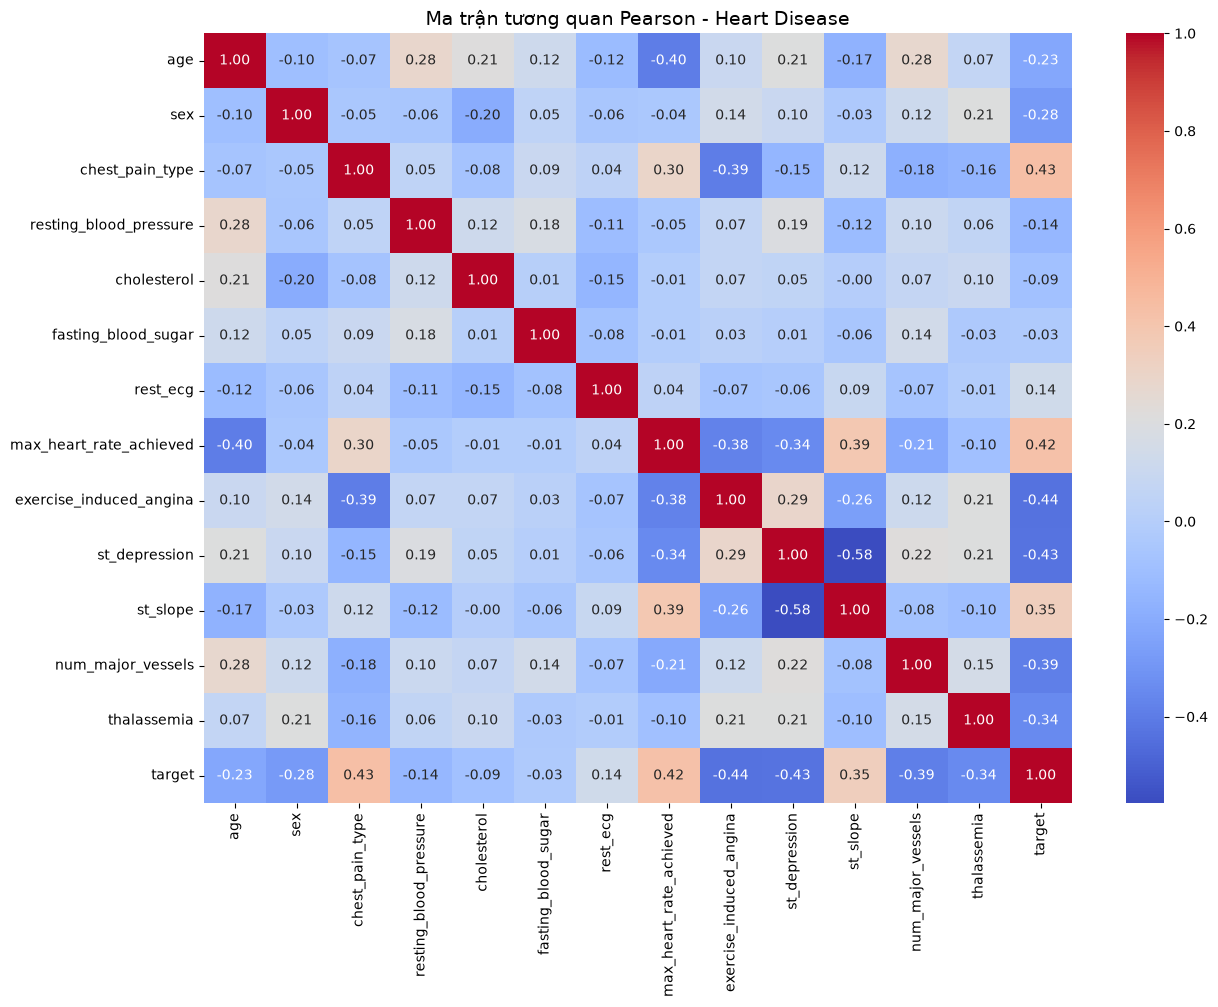

Nhận xét: Độ tương quan giữa các cặp thuộc tính đều ở mức trung bình/thấp (cao nhất là st_depression và st_slope khoảng -0.58), nên không cần loại bỏ cột nào.


In [3]:
print("Trần Nhất Long - 6451071042")
plt.figure(figsize=(14, 10))
corr_matrix = data.corr(method="pearson", numeric_only=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Ma trận tương quan Pearson - Heart Disease", fontsize=14)
plt.show()

print("Nhận xét: Độ tương quan giữa các cặp thuộc tính đều ở mức trung bình/thấp (cao nhất là st_depression và st_slope khoảng -0.58), nên không cần loại bỏ cột nào.")

## Câu 4: Tách các cột thành thuộc tính đầu vào (`features`) và thuộc tính quyết định (`target`)

In [4]:
print("Trần Nhất Long - 6451071042")
features = data.drop("target", axis=1)
labels = data["target"]
print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("Phân bố nhãn target:")
print(labels.value_counts())

Trần Nhất Long - 6451071042
Kích thước features: (303, 13)
Kích thước labels: (303,)
Phân bố nhãn target:
target
1    165
0    138
Name: count, dtype: int64


## Câu 5: Kiểm tra các cột không phải dạng số và chuyển đổi one-hot (nếu có)

In [5]:
print("Trần Nhất Long - 6451071042")
non_numeric_cols = features.select_dtypes(exclude=["int64", "float64"]).columns
print("Các cột không phải dạng số:", list(non_numeric_cols))
if len(non_numeric_cols) > 0:
    features_onehot = pd.get_dummies(features, columns=non_numeric_cols)
else:
    features_onehot = features.copy()
    print("Tất cả các cột thuộc tính đều ở dạng số (int64/float64), không cần chuyển đổi one-hot.")
features_onehot.head()

Trần Nhất Long - 6451071042
Các cột không phải dạng số: []
Tất cả các cột thuộc tính đều ở dạng số (int64/float64), không cần chuyển đổi one-hot.


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


## Câu 6: Chia dữ liệu thành tập huấn luyện (70%) và tập kiểm thử (30%)

In [6]:
print("Trần Nhất Long - 6451071042")
X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

Trần Nhất Long - 6451071042
X_train: (212, 13) | y_train: (212,)
X_test: (91, 13) | y_test: (91,)


## Câu 7: Xây dựng cây ID3 (`criterion='entropy'`), ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042
Accuracy (ID3): 0.7252747252747253
Report (ID3):
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



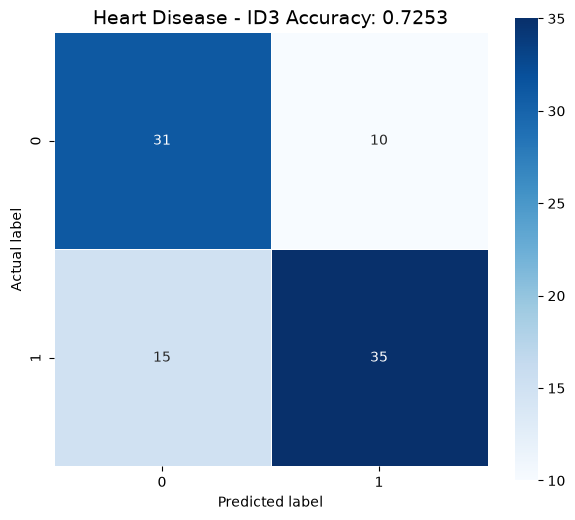

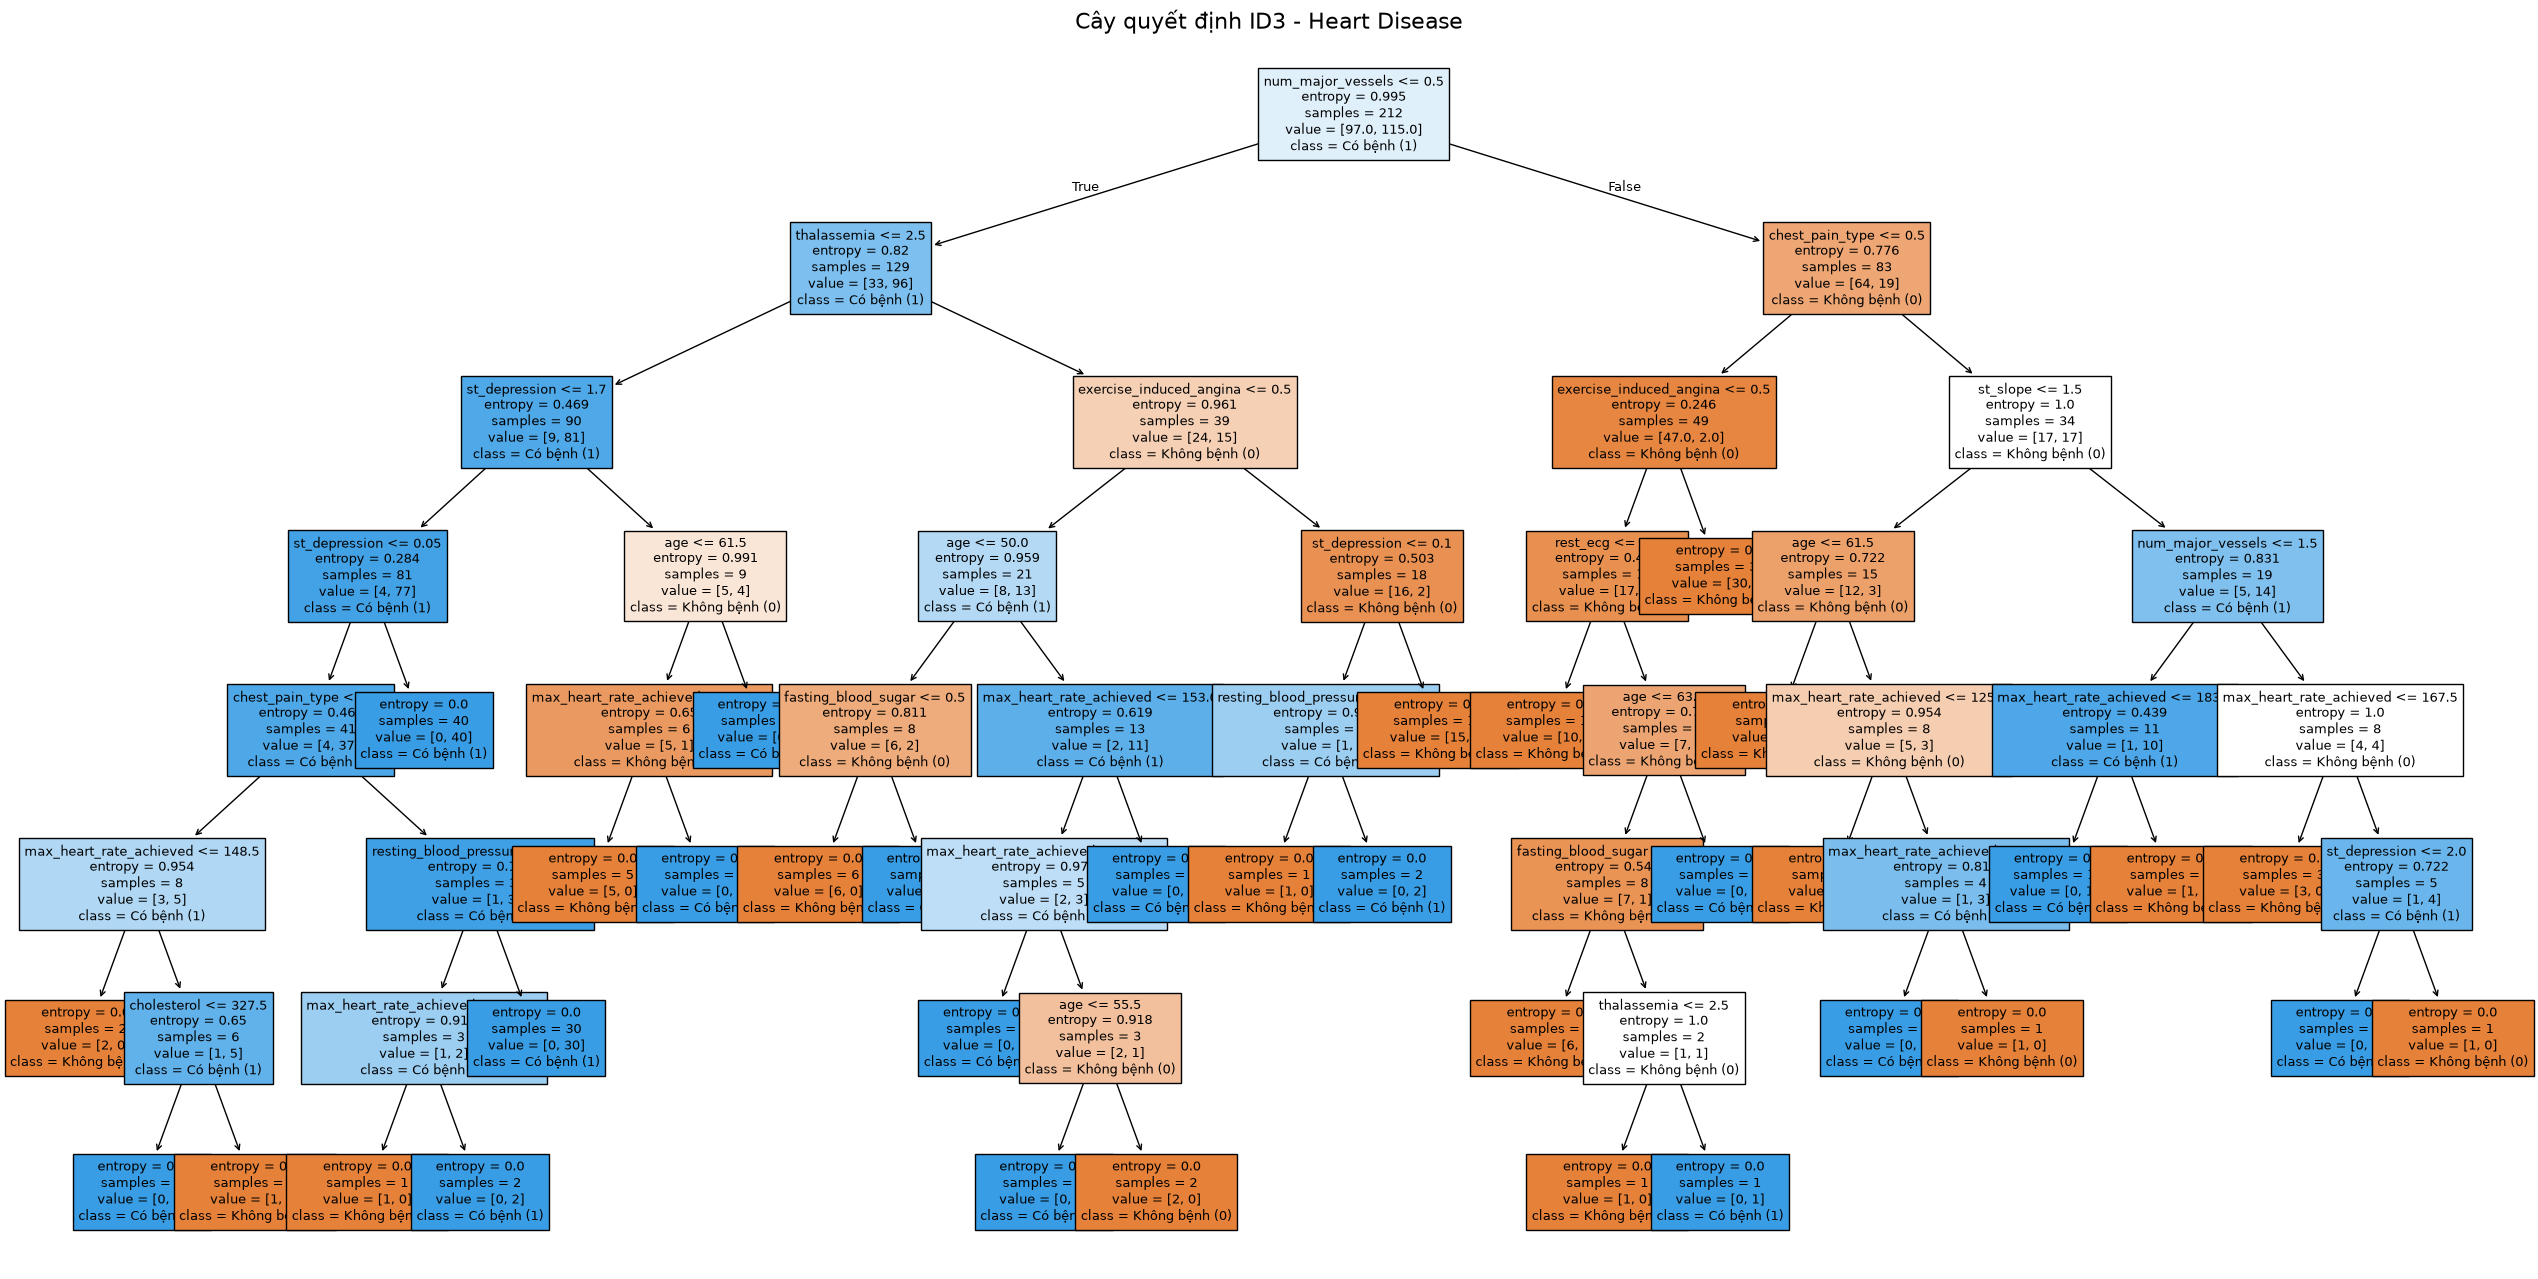

In [7]:
print("Trần Nhất Long - 6451071042")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print("Accuracy (ID3):", id3_score)
print("Report (ID3):\n", metrics.classification_report(y_test, id3_pred))

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Blues")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Heart Disease - ID3 Accuracy: {id3_score:.4f}", size=14)
plt.show()

fig, ax = plt.subplots(figsize=(32, 16))
tree.plot_tree(
    clf_id3,
    feature_names=list(features_onehot.columns),
    class_names=["Không bệnh (0)", "Có bệnh (1)"],
    filled=True,
    fontsize=9,
)
plt.title("Cây quyết định ID3 - Heart Disease", fontsize=16)
plt.savefig("decision_tree_id3_heart.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 8: Xây dựng cây CART (`criterion='gini'`), ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042
Accuracy (CART): 0.7252747252747253
Report (CART):
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



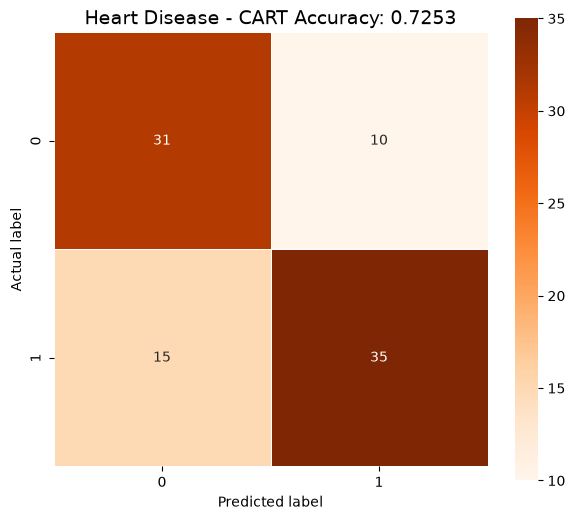

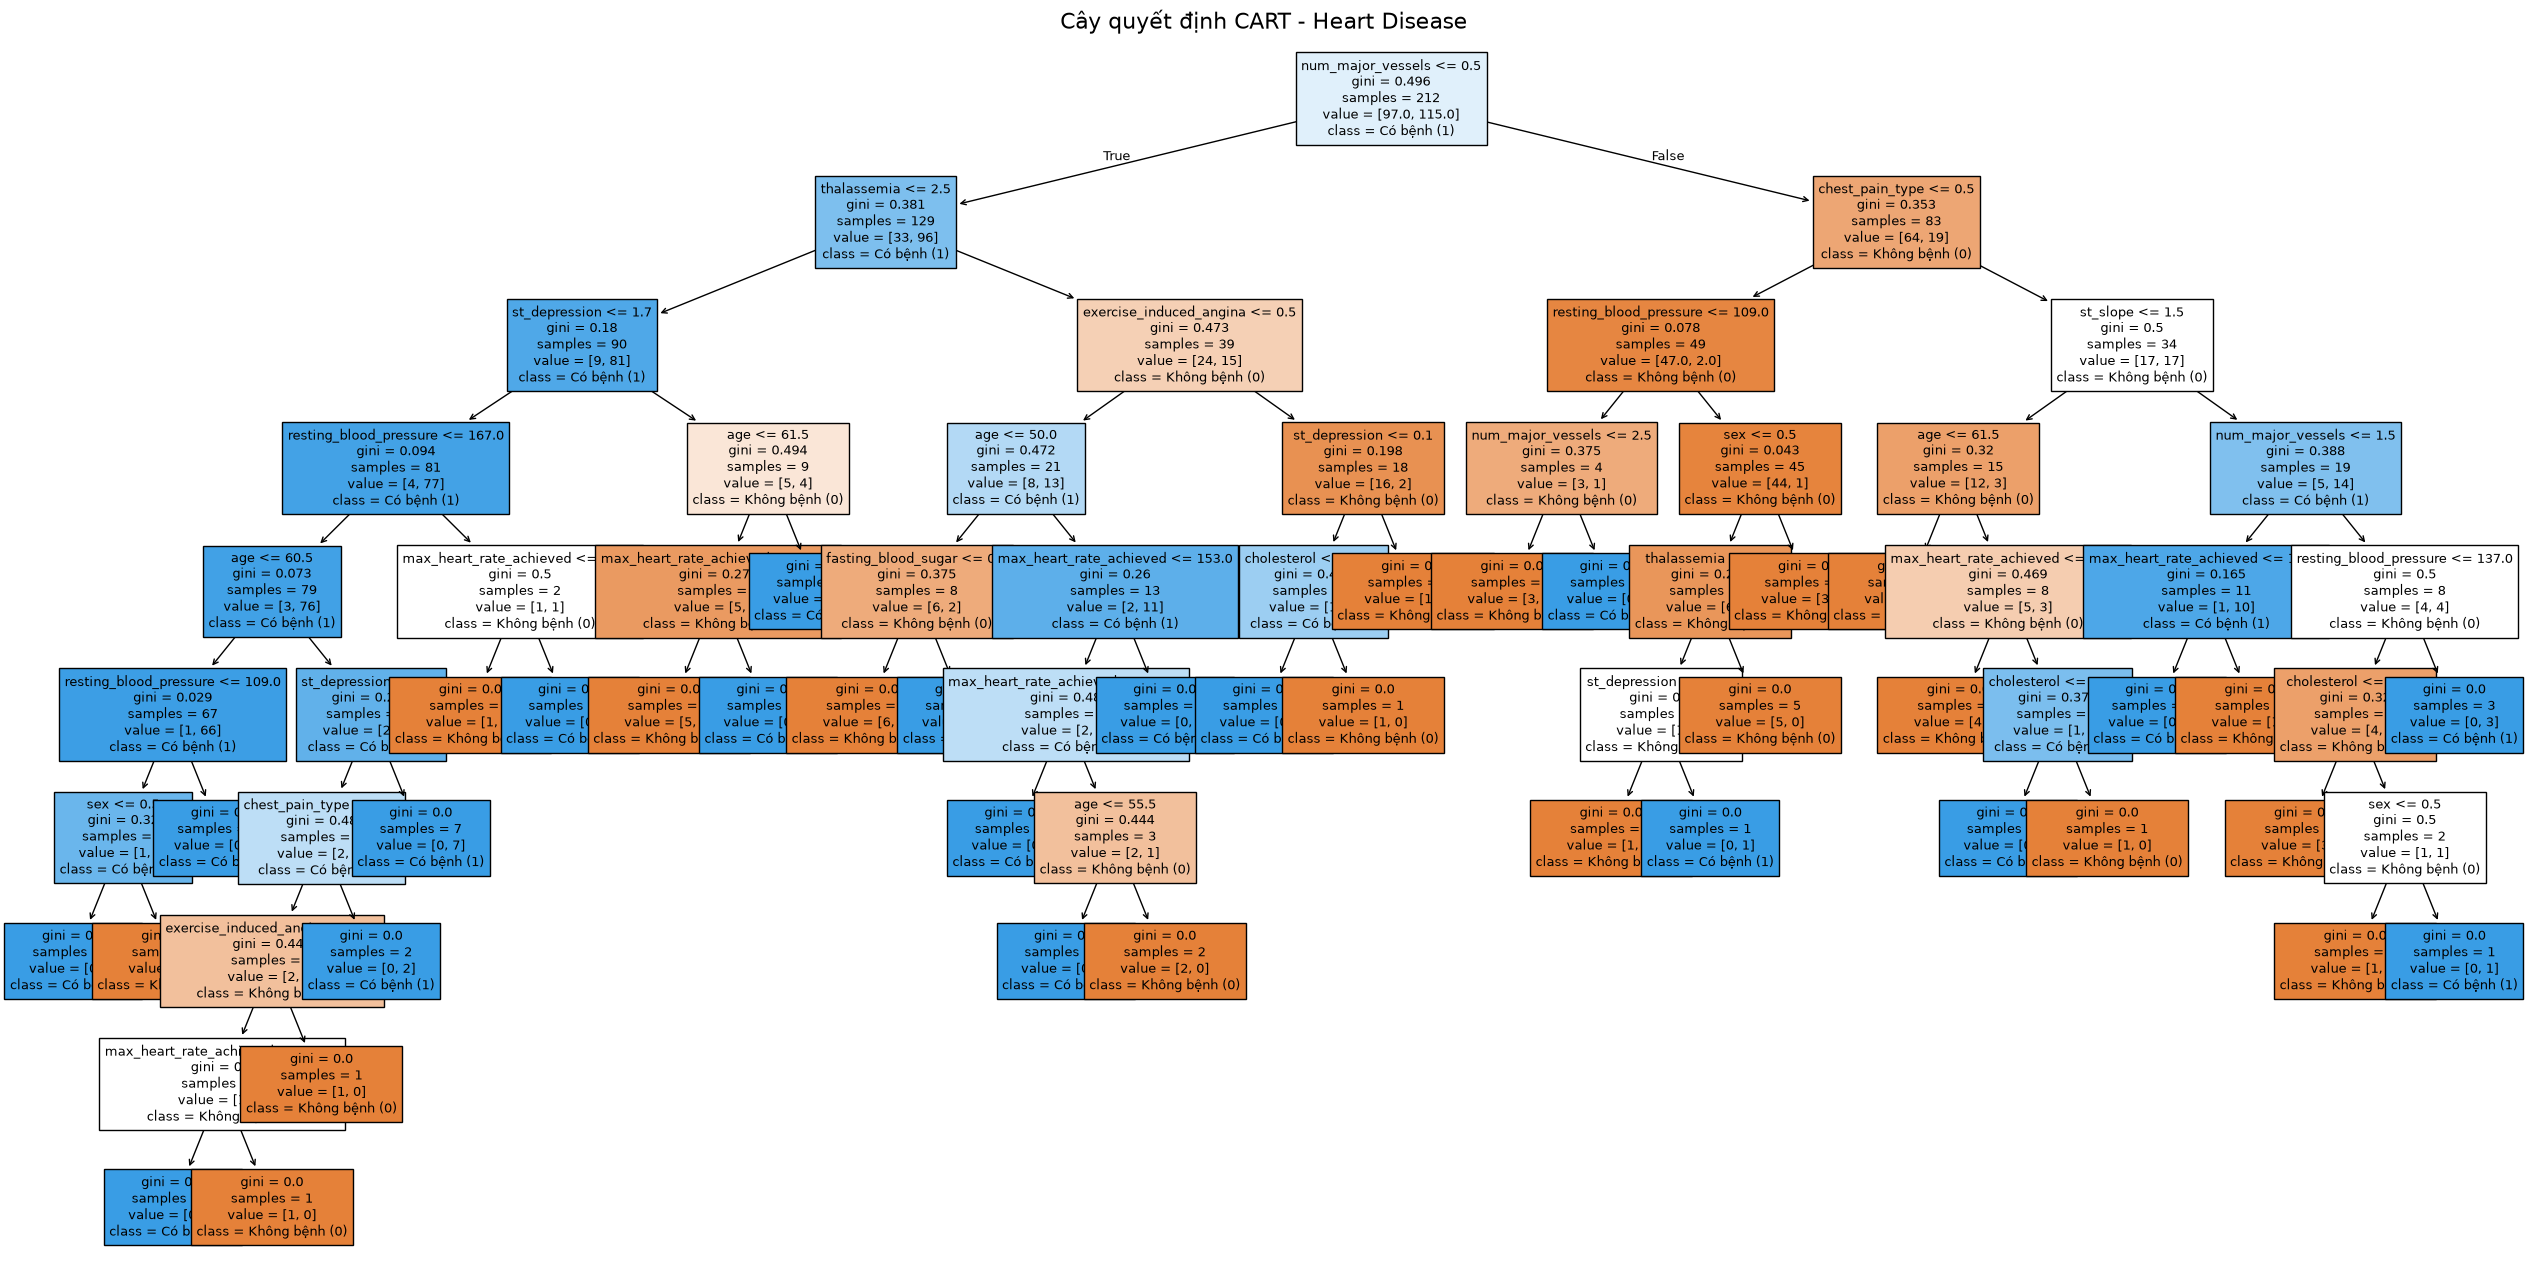

In [8]:
print("Trần Nhất Long - 6451071042")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy (CART):", cart_score)
print("Report (CART):\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Oranges")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Heart Disease - CART Accuracy: {cart_score:.4f}", size=14)
plt.show()

fig, ax = plt.subplots(figsize=(32, 16))
tree.plot_tree(
    clf_cart,
    feature_names=list(features_onehot.columns),
    class_names=["Không bệnh (0)", "Có bệnh (1)"],
    filled=True,
    fontsize=9,
)
plt.title("Cây quyết định CART - Heart Disease", fontsize=16)
plt.savefig("decision_tree_cart_heart.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`) và kiểm tra kết quả

Trần Nhất Long - 6451071042
Accuracy (Naïve Bayes): 0.8351648351648352
Report (Naïve Bayes):
               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



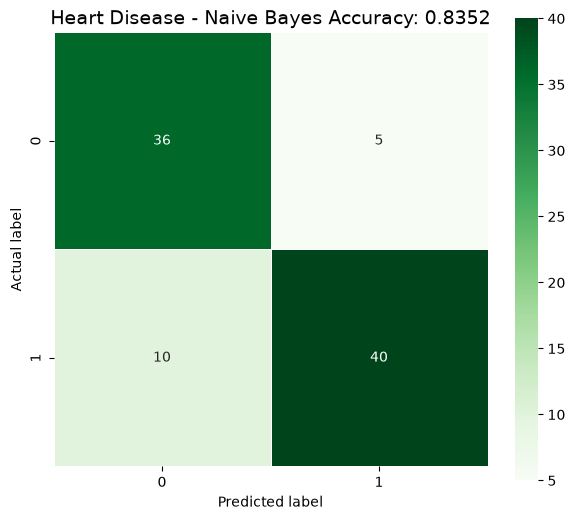

In [9]:
print("Trần Nhất Long - 6451071042")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy (Naïve Bayes):", bayes_score)
print("Report (Naïve Bayes):\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Greens")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Heart Disease - Naive Bayes Accuracy: {bayes_score:.4f}", size=14)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

Trần Nhất Long - 6451071042
                 Mô hình  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)
           ID3 (Entropy)  0.725275           0.725845        0.728049          0.724743
             CART (Gini)  0.725275           0.725845        0.728049          0.724743
Naïve Bayes (GaussianNB)  0.835165           0.835749        0.839024          0.834846


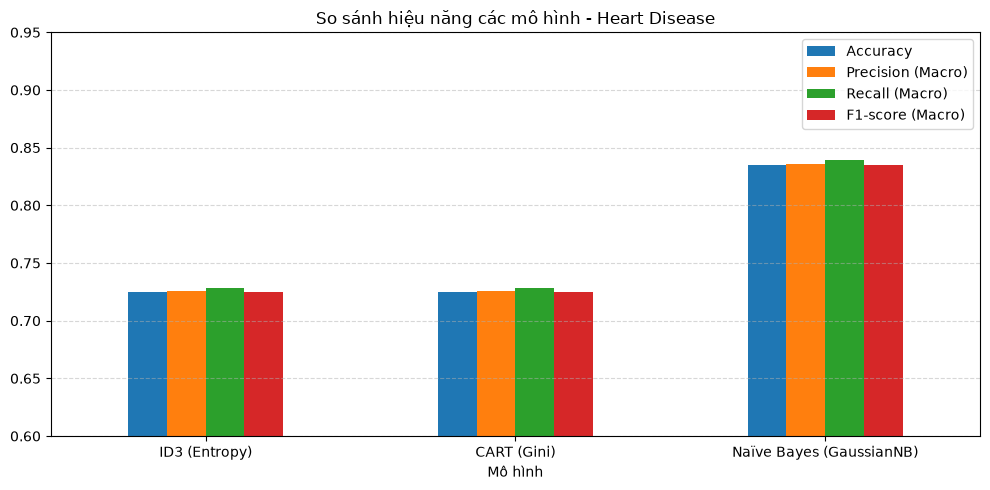


Nhận xét:
- Naïve Bayes đạt độ chính xác cao hơn hai mô hình cây quyết định trên tập dữ liệu Heart Disease (kích thước nhỏ 303 mẫu).
- Cây quyết định không cắt tỉa dễ bị quá khớp (overfitting) khi số lượng mẫu huấn luyện ít (~212 mẫu), trong khi Naïve Bayes tổng quát hóa tốt hơn.


In [10]:
print("Trần Nhất Long - 6451071042")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naïve Bayes (GaussianNB)", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": metrics.accuracy_score(y_test, pred),
        "Precision (Macro)": metrics.precision_score(y_test, pred, average="macro"),
        "Recall (Macro)": metrics.recall_score(y_test, pred, average="macro"),
        "F1-score (Macro)": metrics.f1_score(y_test, pred, average="macro"),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))

df_compare.set_index("Mô hình").plot(kind="bar", figsize=(10, 5), ylim=(0.6, 0.95))
plt.title("So sánh hiệu năng các mô hình - Heart Disease")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("\nNhận xét:")
print("- Naïve Bayes đạt độ chính xác cao hơn hai mô hình cây quyết định trên tập dữ liệu Heart Disease (kích thước nhỏ 303 mẫu).")
print("- Cây quyết định không cắt tỉa dễ bị quá khớp (overfitting) khi số lượng mẫu huấn luyện ít (~212 mẫu), trong khi Naïve Bayes tổng quát hóa tốt hơn.")